# 02 机器学习：外部光伏数据训练与 03 数据迁移

本 Notebook 完成课程要求的“网络数据集 → 训练模型 → 分析教师数据”闭环：

1. 读取 Kaggle Solar Power Generation 的 Plant 1 发电与气象数据；
2. 训练“辐照度/气温 → 光伏容量因子”回归模型；
3. 在外部测试集上评估；
4. 迁移到教师 03 数据，比较物理折算与 ML 曲线；
5. 用两条曲线分别跑基准方案，观察成本与绿电变化。

> 这是跨区域迁移实验，不代表目标电站的真实功率曲线。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print('project root:', ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.ml.pv import (
    training_frame, train_and_save, model_info, load_artifact,
    compare_on_scenario, apply_to_scenario, FEATURES,
)
from src.loader import load_scenario_a
from src.simulate import SimulationParams, simulate

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 120)

print('模型信息：')
print(json.dumps(model_info(), ensure_ascii=False, indent=2)[:1200])

project root: C:\Users\毛\Desktop\python数据分析\实验九\源网荷储一体化仿真平台


模型信息：
{
  "dataset": "Kaggle Solar Power Generation Data (Plant 1)",
  "dataset_url": "https://www.kaggle.com/datasets/anikannal/solar-power-generation-data",
  "license_note": "课程实验迁移分析；原始数据版权归数据集作者，不随项目再分发。",
  "plant_capacity_mw": 30.0,
  "features": [
    "irradiance_kw_m2",
    "ambient_temp_c",
    "hour_sin",
    "hour_cos"
  ],
  "rows": 3157,
  "target": "AC_POWER 聚合 / 30 MW 装机，裁剪到 [0,1]",
  "model": "RandomForestRegressor(n_estimators=240, max_depth=12)",
  "split": "按日期前 80%/后 20% 时序切分",
  "metrics": {
    "train_rows": 2487,
    "test_rows": 670,
    "train_start": "2020-05-15 00:00:00",
    "train_end": "2020-06-10 23:45:00",
    "test_start": "2020-06-11 00:00:00",
    "test_end": "2020-06-17 23:45:00",
    "mae": 0.007664284642077973,
    "rmse": 0.015613094299471986,
    "r2": 0.9964320776352138,
    "baseline_mae": 0.03786033050937788,
    "baseline_rmse": 0.061508929024678145,
    "physical_mae_note": "物理基线为 irradiance*0.82，仅作同测试集对照"
  },
  "trained_at": "2026-10-22T1

## 1. 外部训练数据

如果本地还没有数据，先运行 `python scripts/prepare_external_solar.py`。

In [ ]:
frame = training_frame()
print('形状：', frame.shape)
print('时间：', frame['timestamp'].min(), '->', frame['timestamp'].max())
frame[['timestamp', 'irradiance_kw_m2', 'ambient_temp_c', 'cf']].head()

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(frame['irradiance_kw_m2'], frame['cf'], s=5, alpha=0.35, color='#f5c451')
ax[0].set_xlabel('Irradiance (kW/m2)')
ax[0].set_ylabel('PV capacity factor')
ax[0].set_title('External plant: irradiance vs CF')
ax[1].hist(frame['cf'], bins=30, color='#34d6e8')
ax[1].set_xlabel('PV capacity factor')
ax[1].set_title('CF distribution')
plt.tight_layout()
plt.show()

## 2. 训练与外部测试

按日期前 80% / 后 20% 时序切分，避免同一小时泄漏。

In [ ]:
meta = train_and_save()
print(json.dumps(meta['metrics'], ensure_ascii=False, indent=2))

In [ ]:
artifact = load_artifact()
model = artifact['model']
importance = pd.Series(model.feature_importances_, index=artifact['features']).sort_values()
importance.plot(kind='barh', color='#34d6e8', figsize=(6, 3))
plt.title('Feature importance')
plt.xlabel('Importance')
plt.show()

## 3. 迁移到教师 03 数据

输入 03 的 GHI 与温度，输出光伏容量因子；与物理折算 `GHI/1000×0.82` 对照。

In [ ]:
scenario = load_scenario_a()
cmp = compare_on_scenario(scenario)
summary = {k: v for k, v in cmp.items() if k not in {'timestamps', 'ml_cf', 'physical_cf', 'ghi_wm2', 'temp_c'}}
print(json.dumps(summary, ensure_ascii=False, indent=2))

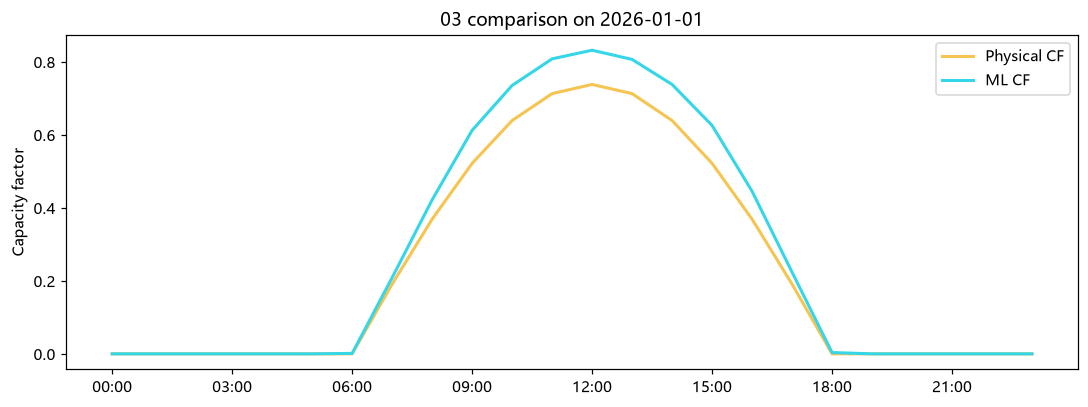

In [7]:
# 选 GHI 总量最大的一天展示
ts = pd.to_datetime(cmp['timestamps'])
ghi = np.array(cmp['ghi_wm2'])
df = pd.DataFrame({'ts': ts, 'ghi': ghi})
day = df.groupby(df['ts'].dt.date)['ghi'].sum().idxmax()
mask = df['ts'].dt.date == day
idx = np.where(mask)[0]
hours = ts[idx].strftime('%H:%M')

plt.figure(figsize=(10, 3.8))
plt.plot(hours, np.array(cmp['physical_cf'])[idx], label='Physical CF', color='#f5c451', lw=2)
plt.plot(hours, np.array(cmp['ml_cf'])[idx], label='ML CF', color='#34d6e8', lw=2)
plt.xticks(range(0, 24, 3))
plt.ylabel('Capacity factor')
plt.title(f'03 comparison on {day}')
plt.legend()
plt.tight_layout()
plt.show()

## 4. 用 ML 曲线重跑基准方案

基准容量 50 MW 风 / 80 MW 光 / 20 MW·80 MWh 储。

In [8]:
params = SimulationParams(C_w=50, C_pv=80, C_b=20, E_b=80)
base = simulate(scenario, params)
ml = simulate(apply_to_scenario(scenario), params)

rows = [
    ('年化总成本（万元/年）', base.annual_cost / 1e4, ml.annual_cost / 1e4),
    ('LCOE（元/kWh）', base.lcoe, ml.lcoe),
    ('弃电率', base.curtail_rate, ml.curtail_rate),
    ('绿电占比', base.green_ratio, ml.green_ratio),
]
for name, a, b in rows:
    print(f'{name:18s} 物理 {a:10.4f}   ML {b:10.4f}   差 {b-a:+.4f}')

年化总成本（万元/年）        物理 21340.1168   ML 19643.4136   差 -1696.7032
LCOE（元/kWh）        物理     0.5034   ML     0.4634   差 -0.0400
弃电率                物理     0.0000   ML     0.0000   差 +0.0000
绿电占比               物理     0.5324   ML     0.5577   差 +0.0253


## 5. 结论与局限

- 外部测试集 R² 约 0.996、MAE 约 0.0077；迁移到 03 后两条曲线相关系数约 0.9997。
- ML 平均 CF 约 0.269，高于物理的 0.234；用 ML 曲线重跑基准方案，年化成本约从 2.13 亿元降到 1.96 亿元。
- 外部数据只有 33 天、位于印度，目标数据在江苏沿海；存在域偏移，ML 只作为对照，不作为主结论。
- 物理折算 + 规则调度 + PSO/GWO 仍是平台主链路。